# Evaluating the validity and results of an A/B test

In [193]:
# import the libraries needed for the analysis:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from plotly import graph_objects as go
import plotly.express as px
import math as mth
import warnings
import scipy.stats as st
import seaborn as sns

## Goal

Assess whether the test was run correctly and evaluate its results

## Analysis plan

● Data overview (read the datasets, count users, check the date ranges). Check whether the data are sufficient to evaluate the test.

● Data preprocessing
Missing values

Duplicates

Data types

● Check the data against the technical specification; filter where needed

Filter by date

Filter by test

Filter by region

Check the condition: 15% of new users from the EU region

Assess the effect of the marketing campaign on user activity

Merge the filtered datasets

Count users with no events after registration

Filter out events that happened more than 14 days after registration

Users with a lifetime shorter than 14 days

Check the condition: expected number of participants

● Test analysis

Distribution of users between groups

Median number of events per user by group

Registrations per day by group

Average spend per user

Device distribution by group

Event funnel

Statistical test of the difference in conversion between groups at each funnel step

● Conclusions

● Recommendations

## Data preprocessing

### Data overview

In [194]:
# event data
events = pd.read_csv ('https://code.s3.yandex.net/datasets/final_ab_events.csv')
display(events.head())
events.info()

,user_id,event_dt,event_name,details
0,E1BDDCE0DAFA2679,2020-12-07 20:22:03,purchase,99.99
1,7B6452F081F49504,2020-12-07 09:22:53,purchase,9.99
2,9CD9F34546DF254C,2020-12-07 12:59:29,purchase,4.99
3,96F27A054B191457,2020-12-07 04:02:40,purchase,4.99
4,1FD7660FDF94CA1F,2020-12-07 10:15:09,purchase,4.99


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440317 entries, 0 to 440316
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   user_id     440317 non-null  object 
 1   event_dt    440317 non-null  object 
 2   event_name  440317 non-null  object 
 3   details     62740 non-null   float64
dtypes: float64(1), object(3)
memory usage: 13.4+ MB


In [195]:
events['user_id'].nunique()

58703

In [196]:
events['event_dt'].min()

'2020-12-07 00:00:33'

In [197]:
events['event_dt'].max()

'2020-12-30 23:36:33'

In [198]:
events['event_name'].unique()

array(['purchase', 'product_cart', 'product_page', 'login'], dtype=object)

*The `events` dataset contains 58,703 unique users for the period 7 December to 30 December 2020 and 4 distinct event types.*

*Note: there is not enough data to evaluate 14-day activity for new users who registered between 17 and 21 December.*

In [199]:
# marketing campaign data
marketing_events = pd.read_csv ('https://code.s3.yandex.net/datasets/ab_project_marketing_events.csv')
print(marketing_events.head())
marketing_events.info()

                           name                   regions    start_dt  \
0      Christmas&New Year Promo             EU, N.America  2020-12-25   
1  St. Valentine's Day Giveaway  EU, CIS, APAC, N.America  2020-02-14   
2        St. Patric's Day Promo             EU, N.America  2020-03-17   
3                  Easter Promo  EU, CIS, APAC, N.America  2020-04-12   
4             4th of July Promo                 N.America  2020-07-04   

    finish_dt  
0  2021-01-03  
1  2020-02-16  
2  2020-03-19  
3  2020-04-19  
4  2020-07-11  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   name       14 non-null     object
 1   regions    14 non-null     object
 2   start_dt   14 non-null     object
 3   finish_dt  14 non-null     object
dtypes: object(4)
memory usage: 576.0+ bytes


In [200]:
marketing_events['name'].nunique()

14

In [201]:
marketing_events['regions'].nunique()

6

In [202]:
marketing_events['regions'].unique()

array(['EU, N.America', 'EU, CIS, APAC, N.America', 'N.America', 'APAC',
       'EU, CIS, APAC', 'CIS'], dtype=object)

In [203]:
marketing_events['start_dt'].min()

'2020-01-25'

In [204]:
marketing_events['start_dt'].max()

'2020-12-30'

In [205]:
marketing_events['finish_dt'].min()

'2020-02-07'

In [206]:
marketing_events['finish_dt'].max()

'2021-01-07'

*The `marketing_events` dataset describes marketing campaigns run in 6 region groups (some regions appear in more than one group) between 25 January 2020 and 7 January 2021.*

In [207]:
# user registration data
new_users = pd.read_csv ('https://code.s3.yandex.net/datasets/final_ab_new_users.csv')
print(new_users.head())
new_users.info()

            user_id  first_date     region   device
0  D72A72121175D8BE  2020-12-07         EU       PC
1  F1C668619DFE6E65  2020-12-07  N.America  Android
2  2E1BF1D4C37EA01F  2020-12-07         EU       PC
3  50734A22C0C63768  2020-12-07         EU   iPhone
4  E1BDDCE0DAFA2679  2020-12-07  N.America   iPhone
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61733 entries, 0 to 61732
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     61733 non-null  object
 1   first_date  61733 non-null  object
 2   region      61733 non-null  object
 3   device      61733 non-null  object
dtypes: object(4)
memory usage: 1.9+ MB


In [208]:
new_users['user_id'].nunique()

61733

In [209]:
new_users['first_date'].min()

'2020-12-07'

In [210]:
new_users['first_date'].max()

'2020-12-23'

In [211]:
new_users['region'].nunique()

4

In [212]:
new_users['region'].unique()

array(['EU', 'N.America', 'APAC', 'CIS'], dtype=object)

In [213]:
new_users['device'].unique()

array(['PC', 'Android', 'iPhone', 'Mac'], dtype=object)

In [214]:
new_users['device'].nunique()

4

*The `new_users` dataset contains 61,733 unique users who registered between 7 December 2020 and 23 December 2020 in 4 regions on 4 device types.*

In [215]:
# test assignment data
participants = pd.read_csv ('https://code.s3.yandex.net/datasets/final_ab_participants.csv')
print(participants.head())
participants.info()

            user_id group                  ab_test
0  D1ABA3E2887B6A73     A  recommender_system_test
1  A7A3664BD6242119     A  recommender_system_test
2  DABC14FDDFADD29E     A  recommender_system_test
3  04988C5DF189632E     A  recommender_system_test
4  482F14783456D21B     B  recommender_system_test
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18268 entries, 0 to 18267
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  18268 non-null  object
 1   group    18268 non-null  object
 2   ab_test  18268 non-null  object
dtypes: object(3)
memory usage: 428.3+ KB


In [216]:
participants['user_id'].nunique()

16666

In [217]:
participants['group'].unique()

array(['A', 'B'], dtype=object)

In [218]:
participants['ab_test'].unique()

array(['recommender_system_test', 'interface_eu_test'], dtype=object)

*The `participants` dataset contains 16,666 unique users assigned to groups A and B across 2 different A/B tests.*

### Column names

*All datasets use snake_case column names.*

### Missing values

In [219]:
events.isna().sum()

user_id            0
event_dt           0
event_name         0
details       377577
dtype: int64

*Missing values were found in the `details` column, which holds purchase amounts.
The test evaluates the change in purchase conversion, not purchase value, so these missing values were left as they are.*

In [220]:
marketing_events.isna().sum()

name         0
regions      0
start_dt     0
finish_dt    0
dtype: int64

In [221]:
new_users.isna().sum()

user_id       0
first_date    0
region        0
device        0
dtype: int64

In [222]:
participants.isna().sum()

user_id    0
group      0
ab_test    0
dtype: int64

### Duplicates

In [223]:
events.duplicated().sum()

0

In [224]:
marketing_events.duplicated().sum()

0

In [225]:
new_users.duplicated().sum()

0

In [226]:
participants.duplicated().sum()

0

*No exact duplicates were found in any dataset.*

### Data types

In [227]:
# Convert data types to the required format
events['event_dt'] = pd.to_datetime(events['event_dt'])
marketing_events['start_dt'] = pd.to_datetime(marketing_events['start_dt'])
marketing_events['finish_dt'] = pd.to_datetime(marketing_events['finish_dt'])
new_users['first_date'] = pd.to_datetime(new_users['first_date'])

## Checking the data against the technical specification; filtering where needed

### Filtering by date

#### new_users

In [228]:
# Slice new_users according to the specification.
new_users_filtered_date = new_users.query('first_date <"2020-12-22"')

*The earliest registration date in `new_users` (2020-12-07) matches the specification. We slice only by the end date of new-user recruitment.*

In [229]:
new_users_filtered_date['user_id'].nunique()

56470

In [230]:
lost_by_date = (events['user_id'].nunique()-new_users_filtered_date['user_id'].nunique())*100/new_users['user_id'].nunique()
lost_by_date

3.617190157614242

*Filtering by registration date removed 3.6% of unique users from `new_users`.*

#### events

*The specification expects users to show improvement in each metric within 14 days of registration. The `events` slice should therefore run from the earliest registration date + 14 days (21 December 2020) to the latest registration date + 14 days (4 January 2021).*

*`events` covers 7 December to 30 December 2020, so no slicing is needed.*

#### marketing_events

*To trace the effect of marketing campaigns, exclude campaigns that did NOT run between 7 December 2020 (earliest registration) and 4 January 2021 (latest registration + 14 days).*

In [231]:
# Keep only campaigns that ran during the test period
marketing_events_filtered_by_date = marketing_events[(marketing_events['start_dt'] < '2021-01-05') & (marketing_events['finish_dt'] > '2020-12-06') & (marketing_events['finish_dt'] < '2021-01-05')]

In [232]:
marketing_events_filtered_by_date

,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03


*Only one marketing campaign ran during the test. Its region ('EU, N.America') matches the specification, so no additional filtering by region is needed.*

### Filtering by test

*The `participants` dataset contains 2 tests, each splitting users into groups A and B.
Another test, `interface_eu_test`, ran at the same time. We check whether users overlapped between the two tests.*

In [233]:
participans_intersection = participants.pivot_table(index='user_id', values='ab_test', aggfunc='count')
participans_intersection[participans_intersection['ab_test']==2].count() 

ab_test    1602
dtype: int64

*1,602 users took part in both tests at the same time.*
*Group A is the control group and receives almost no intervention, so excluding group A users of `interface_eu_test` is not justified.*
*To decide whether to remove group B users of `interface_eu_test`, we look at how they are distributed between groups A and B of `recommender_system_test`.*

In [234]:
# List the users assigned to group B of interface_eu_test
participants_interface_b = participants.query('ab_test == "interface_eu_test" and group == "B"')
interface_b_list = participants_interface_b['user_id'].tolist()

In [235]:
# Slice participants for group A of recommender_system_test
participants_recommender_a = participants.query('ab_test == "recommender_system_test" and group == "A"')

In [236]:
# Intersection: group A of recommender_system_test with group B of interface_eu_test
ba_test = participants_recommender_a['user_id'].isin(interface_b_list)
ba_test.value_counts()

False    3385
True      439
Name: user_id, dtype: int64

In [237]:
# Slice participants for group B of recommender_system_test
participants_recommender_b = participants.query('ab_test == "recommender_system_test" and group == "B"')

In [238]:
# Intersection: group B of recommender_system_test with group B of interface_eu_test
bb_test = participants_recommender_b['user_id'].isin(interface_b_list)
bb_test.value_counts()

False    2533
True      344
Name: user_id, dtype: int64

In [239]:
# Share of interface_eu_test group B users inside recommender_system_test group A
participants_test_clear = participants.query('ab_test == "recommender_system_test"')
participants_test_clear['user_id'].nunique()

6701

In [240]:
ba_test_percent = (ba_test.value_counts()/participants_test_clear['user_id'].nunique())*100
ba_test_percent

False    50.514849
True      6.551261
Name: user_id, dtype: float64

In [241]:
bb_test_percent = (bb_test.value_counts()/participants_test_clear['user_id'].nunique())*100
bb_test_percent

False    37.800328
True      5.133562
Name: user_id, dtype: float64

*Users from group B of `interface_eu_test` make up 6.5% of group A and 5.1% of group B of `recommender_system_test`.*

*Because they are distributed almost evenly between groups A and B, we decided not to exclude them from further analysis.*

In [242]:
 # Final slice by test based on the results above
participants_final = participants.query('ab_test == "recommender_system_test"')

### Filtering by region

In [243]:
# Filter the new_users dataset that was already filtered by date
new_users_filtered_by_region_and_date = new_users_filtered_date.query('region == "EU"')

In [244]:
# Count how many users were removed at this step
lost_new_users_by_region = (new_users_filtered_date['user_id'].nunique()-new_users_filtered_by_region_and_date['user_id'].nunique())*100/new_users_filtered_date['user_id'].nunique()
lost_new_users_by_region

25.022135647246326

*Filtering `new_users` by region removed 25% of users.*

### Checking the condition: 15% of new users from the EU region

In [245]:
# To estimate the share of EU participants, join new_users_filtered_by_region_and_date with participants_final
join_part_new_users = participants_final.merge(new_users_filtered_by_region_and_date, on='user_id')

To estimate the share of EU users registered in the test during the specified dates, divide the number of unique users in the filtered dataset (by test, region and dates) by the number of unique users registered in the EU during those dates.

In [246]:
round(join_part_new_users['user_id'].nunique()/new_users_filtered_by_region_and_date['user_id'].nunique()*100)

15

*The share of EU users registered during the specified dates in `recommender_system_test` is 15%, which matches the specification.*

### Assessing the effect of the marketing campaign on user activity

In [247]:
# round event timestamps to the day
events['event_dt'] = events['event_dt'].dt.date

In [248]:
# count events per day over the study period
events_by_day = events.pivot_table(index = 'event_dt', values = ['event_name'], aggfunc = 'count')
events_by_day =  events_by_day.reset_index()

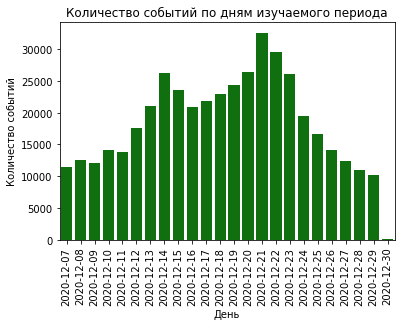

In [249]:
# Visualize the result
# bar chart
ax = sns.barplot(x='event_dt', y='event_name', data=events_by_day, color='green')
plt.title ('Number of events per day over the study period')
plt.ylabel ('Number of events')
plt.xlabel ('Day')
plt.xticks(rotation=90);

*The marketing campaign in this region started on 25 December 2020. No sharp jumps in user activity were observed after that date.
No additional filtering is needed.*

### Merging the tables

*For further analysis we merge 3 datasets: `events`, `new_users_filtered_by_region_and_date` and `participants_test`. Only users present in all 3 datasets are kept, because evaluating the test's validity, results and compliance with the specification requires data from all three.*

*We use an inner merge on `user_id`.*

### participants_final and events

In [250]:
# Merge the dataframes
join_part_events = participants_final.merge(events, on='user_id')
# Data loss at this step as a share of all recommender_system_test users
lost_join_part_events = round((participants_final['user_id'].nunique() - join_part_events['user_id'].nunique())/participants_final['user_id'].nunique()*100)
print('Loss when merging participants_final and events:', lost_join_part_events, '%')

Потери на этапе объединения таблиц participants_final и events составляют 45 %


### new_users_filtered_by_region_and_date and the merged join_part_events

In [251]:
# Merge the dataframes
join_all = join_part_events.merge(new_users_filtered_by_region_and_date, on='user_id')
# Data loss at this step as a share of all recommender_system_test users
lost_join_all = round((participants_final['user_id'].nunique() - join_all['user_id'].nunique())/participants_final['user_id'].nunique()*100)
print('Loss when merging new_users_filtered_by_region_and_date and join_part_events:', lost_join_all,  '%')

Потери на этапе объединения таблиц new_users_filtered_by_region_and_date и join_part_events составляют 48 %


In [252]:
# Check the merged dataframe for missing values
join_all.isna().sum()

user_id           0
group             0
ab_test           0
event_dt          0
event_name        0
details       20224
first_date        0
region            0
device            0
dtype: int64

*Missing values remain only in `details`. This column does not affect the validity or effect analysis, so the missing values were left unchanged.*

### Users with no actions after registration

In [253]:
# Pivot table: number of events per user
count_events_by_users = join_all.pivot_table(index='user_id', values='event_name', aggfunc='count')

In [254]:
# Remove users who performed only 1 event
count_events_by_users_active = count_events_by_users.query('event_name >1')
count_events_by_users_active = count_events_by_users_active.reset_index()
# Count users who only registered and performed no further events
count_events_by_users_active['user_id'].nunique()

3430

In [255]:
# Share of users lost at this step
part_active_users = ((join_all['user_id'].nunique() - count_events_by_users_active['user_id'].nunique())/join_all['user_id'].nunique())*100
part_active_users

1.465096236713588

*96 users (1.19%) of the specification-filtered dataset performed no events after registration. Inactive users were excluded.*

### Filtering out events that happened more than 14 days after registration

In [256]:
# convert date columns to the format needed for the calculations
join_all['event_dt'] = pd.to_datetime(join_all['event_dt'])
join_all['event_dt'] = join_all['event_dt'].dt.date
join_all['first_date'] = join_all['first_date'].dt.date

In [257]:
# days between registration and event, as a number
join_all['day_of_event'] = (join_all['event_dt'] - join_all['first_date'])/np.timedelta64(1, 'D')

In [258]:
# Keep events that happened within 14 days of registration (days 0 to 13)
test_filtered = join_all.query('day_of_event < 14')

### Users with a lifetime shorter than 14 days

*The datasets contain no events after 30 December 2020, so for users registered after 16 December the full 14-day observation window cannot be evaluated.*

*To decide whether to filter out users with a lifetime under 14 days, we look at the distribution of user activity by day.*

In [259]:
# Average day on which a user performs an action
join_all_events_count = test_filtered.pivot_table(index='user_id', values='day_of_event', aggfunc=['mean'])
join_all_events_count = join_all_events_count.reset_index()

In [260]:
# Day on which users most often perform events
join_all_events_count[('mean', 'day_of_event')].describe()

count    3481.000000
mean        2.427678
std         1.683739
min         0.000000
25%         1.000000
50%         2.333333
75%         3.600000
max         9.500000
Name: (mean, day_of_event), dtype: float64

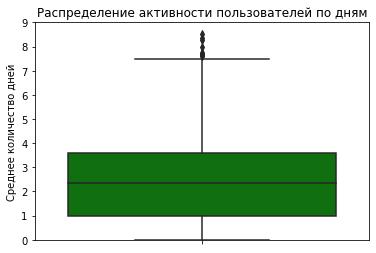

In [261]:
# Visualize the result
boxplot = sns.boxplot(y = ('mean', 'day_of_event'), data = join_all_events_count, color='green')
plt.title('Distribution of user activity by day')
plt.ylim(0, 9)
plt.ylabel ('Average number of days');

*Peak user activity falls on days 2 to 4 after registration.
After day 5 users rarely perform actions. Excluding users whose lifetime is under 14 days but over 5 days is not justified.*

*Activity within 5 days can be evaluated for all users, including those registered on the last recruitment day, 21 December.*

### Checking the condition: expected number of participants (6,000)

In [262]:
test_filtered['user_id'].nunique()

3481

*After sequential filtering by the specification, 3,481 users remain instead of the expected 6,000.*

*This deviation is recorded for the final assessment of the test's validity.*

## Test analysis

### Distribution of participants between groups

In [263]:
test_filtered_a = test_filtered.query('group == "A"')
print('Users registered in group A:', test_filtered_a['user_id'].nunique(), 'users')
test_filtered_a_part = round(test_filtered_a['user_id'].nunique()/test_filtered['user_id'].nunique()*100)
print('Group A users make up', test_filtered_a_part, '% of all test participants')
#events_by_users = test_filtered_A.pivot_table(index='user_id', values='event_name', aggfunc='count')
#events_by_users

В группе А зарегистрировано 2604 пользователя
Пользователи группы А составляют 75 %  от общего количества участников теста


In [264]:
test_filtered_b = test_filtered.query('group == "B"')
print(test_filtered_b['user_id'].nunique())
test_filtered_b_part = round(test_filtered_b['user_id'].nunique()/test_filtered['user_id'].nunique()*100)
print('Group B users make up', test_filtered_b_part, '% of all test participants')

877
Пользователи группы B составляют 25 %  от общего количества участников теста


*The participants are distributed unevenly between groups.*

*A deviation this large can seriously distort the results.*

### Median number of events per user by group

In [265]:
events_by_users_a =  test_filtered_a.pivot_table(index='user_id', values='event_name', aggfunc='count')
events_by_users_a['event_name'].describe()

count    2604.000000
mean        6.849078
std         3.812030
min         1.000000
25%         4.000000
50%         6.000000
75%         9.000000
max        24.000000
Name: event_name, dtype: float64

In [266]:
events_by_users_b =  test_filtered_b.pivot_table(index='user_id', values='event_name', aggfunc='count')
events_by_users_b['event_name'].describe()

count    877.000000
mean       5.456100
std        3.246276
min        1.000000
25%        3.000000
50%        4.000000
75%        8.000000
max       24.000000
Name: event_name, dtype: float64

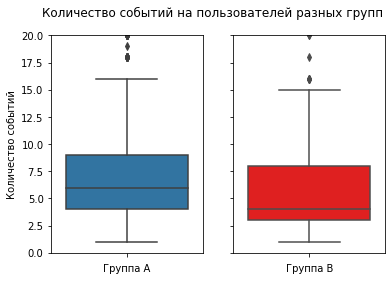

In [267]:
# Plot the results
fig, axes = plt.subplots(1, 2, sharey=True)
boxplot_1 = sns.boxplot(y = 'event_name', data = events_by_users_a,  ax=axes[0])
fig.suptitle('Number of events per user by group')
plt.ylim(0, 20)
axes[0].set_ylabel('Number of events')
axes[0].set_xlabel('Group A')
boxplot_2 = sns.boxplot(y = 'event_name', data = events_by_users_b, ax=axes[1], color='red')
axes[1].set_ylabel(' ')
axes[1].set_xlabel('Group B');

*On average, group A users are more active: the median number of events per user is 6 in group A and 4 in group B.*

### Registrations per day by group

In [268]:
# registrations per day in group A
events_by_day_a = test_filtered_a.pivot_table(index = 'first_date', values = ['user_id'], aggfunc = 'count')

In [269]:
# registrations per day in group B
events_by_day_b = test_filtered_b.pivot_table(index = 'first_date', values = ['user_id'], aggfunc = 'count')

In [270]:
# Prepare the dataframe for plotting
# Rename the registration count columns
events_by_day_a.rename(columns = {'user_id':'new_users_count_a'}, inplace = True )
events_by_day_b.rename(columns = {'user_id':'new_users_count_b'}, inplace = True )
# merge the dataframes for plotting
join_events_by_date = events_by_day_a.join(events_by_day_b, on='first_date', how='left', lsuffix='', rsuffix='', sort=False)

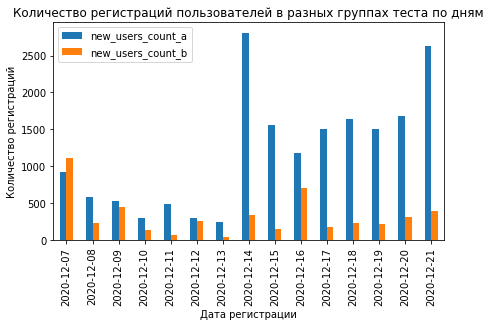

In [271]:
# plot the result
join_events_by_date.plot(kind='bar', figsize=(7, 4))
plt.title ('User registrations per day by test group')
plt.ylabel ('Number of registrations')
plt.xlabel ('Registration date')
plt.xticks(rotation=90);

*There is a sharp increase in group A registrations after 14 December 2020. According to the data, no marketing campaigns ran in the EU at that time. This may be due to external factors (start of the Christmas sales?).*

### Average amount spent per user by group

In [272]:
# Average spend per user, group A
money_filtered_a = test_filtered_a.pivot_table(index='user_id', values = 'details', aggfunc ='sum') 
money_filtered_a['details'].mean()

22.056509216589866

In [273]:
# Average spend per user, group B
money_filtered_b = test_filtered_b.pivot_table(index='user_id', values = 'details', aggfunc ='sum') 
money_filtered_b['details'].mean()

16.23012542759407

*Average spend per user is higher in group A. However, given the deviations found earlier (uneven group sizes, too few participants, a lower share of EU users than expected, and the sharp rise in group A activity after 14 December that may be linked to the holiday sales), drawing conclusions from this is not justified.*

### Device distribution by group

In [274]:
# number of devices in group A
devices_a = test_filtered_a.pivot_table(index = 'device', values = 'user_id', aggfunc='nunique')
devices_total = devices_a['user_id'].sum()
# share of devices in group A
devices_a['part_a'] = round(devices_a['user_id']/devices_a['user_id'].sum()*100)
devices_a

,user_id,part_a
device,,
Android,1139,44.0
Mac,255,10.0
PC,689,26.0
iPhone,521,20.0


In [275]:
# number of devices in group B
devices_b = test_filtered_b.pivot_table(index = 'device', values = 'user_id', aggfunc='nunique')
devices_total = devices_b['user_id'].sum()
# share of devices in group B
devices_b['part_b'] = round(devices_b['user_id']/devices_b['user_id'].sum()*100)
devices_b

,user_id,part_b
device,,
Android,405,46.0
Mac,74,8.0
PC,212,24.0
iPhone,186,21.0


In [276]:
# Prepare the dataframe for plotting
# Rename the count columns
devices_a.rename(columns = {'user_id':'users_a'}, inplace = True )
devices_b.rename(columns = {'user_id':'users_b'}, inplace = True )
# merge the dataframes for plotting
join_devices = devices_a.join(devices_b, on='device', how='left', lsuffix='', rsuffix='', sort=False)
join_devices_for_plot = join_devices[['part_a', 'part_b']]

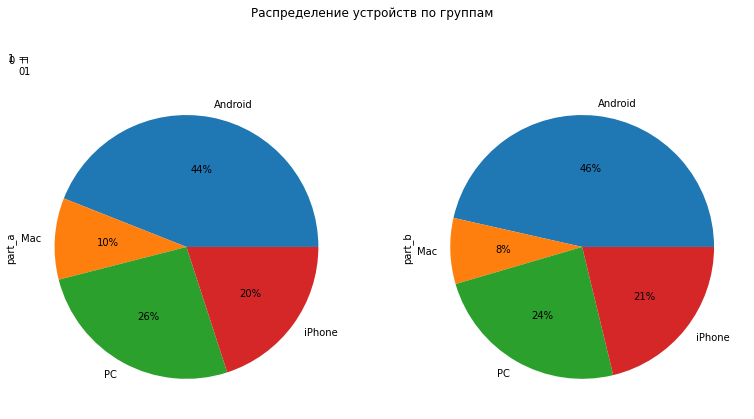

In [277]:
# plot the result
join_devices_for_plot.plot(kind='pie', figsize=(13, 7), subplots=True, legend=False,  autopct='%0.0f%%')
plt.suptitle("Device distribution by group")
plt.subplot(121, 122, 1);

*There are no meaningful differences in device distribution between the groups.*

### Event funnels

In [278]:
# Number of users at each funnel step
# Group A
test_filtered_a_events = test_filtered_a.pivot_table(index = ['event_name'], values = 'user_id', aggfunc='nunique')
# Index the events in logical order
test_filtered_a_events = test_filtered_a_events.reindex(['login', 'product_page','product_cart', 'purchase'])
# add a group label column (for merging and plotting)
test_filtered_a_events['group'] = 'A'
# Number of users at the first step, login
test_filtered_a_events = test_filtered_a_events.reset_index()
users_login_a = test_filtered_a_events.iloc [0]['user_id']
# share of users at each step relative to the first step
test_filtered_a_events['part'] = round(test_filtered_a_events['user_id'].apply(lambda x: x/users_login_a)*100)

In [279]:
# Number of users at each funnel step
# Group B
test_filtered_b_events = test_filtered_b.pivot_table(index = ['event_name'], values = 'user_id', aggfunc='nunique')
# Index the events in logical order
test_filtered_b_events = test_filtered_b_events.reindex(['login', 'product_page','product_cart', 'purchase'])
# add a group label column (for merging and plotting)
test_filtered_b_events['group'] = 'B'
# Number of users at the first step, login
test_filtered_b_events = test_filtered_b_events.reset_index()
users_login_b = test_filtered_b_events.iloc [0]['user_id']
# share of users at each step relative to the first step
test_filtered_b_events['part'] = round(test_filtered_b_events['user_id'].apply(lambda x: x/users_login_b)*100)

In [280]:
# merge the dataframes for plotting
events_for_conversion = pd.concat([test_filtered_a_events, test_filtered_b_events], axis=0)
events_for_conversion = events_for_conversion.reset_index()

In [281]:
# Plot the result
fig = px.funnel(events_for_conversion, x=events_for_conversion['part'], y='event_name', color='group')
fig.update_layout(title='User conversion at each event step by group', title_x = 0.5)
fig.show()

*Funnel conclusion:*

*The expected effect (at least a 10% improvement in every metric within 14 days of registration) was not achieved.
Conversion to product page views (product_page) fell by 9%, to cart views (product_cart) by 2%,
and to purchases (purchase) by 4%.*

### Events by day

In [282]:
# Prepare the dataframes
# Group A
test_filtered_group_a_event_date = test_filtered_a.pivot_table(index=['event_name', 'event_dt'], values='user_id', aggfunc='count')
test_filtered_group_a_event_date = test_filtered_group_a_event_date.reset_index()
# Group B
test_filtered_group_b_event_date = test_filtered_b.pivot_table(index=['event_name', 'event_dt'], values='user_id', aggfunc='count')
test_filtered_group_b_event_date = test_filtered_group_b_event_date.reset_index()

In [283]:
# Plot the result

figA = px.bar(test_filtered_group_a_event_date, x=test_filtered_group_a_event_date['event_dt'], y='user_id', color='event_name')
figA.update_layout(title='Events by day, group A')
figA.show()

figB = px.bar(test_filtered_group_b_event_date, x=test_filtered_group_b_event_date['event_dt'], y='user_id', color='event_name')
figB.update_layout(title='Events by day, group B')
figB.show()

*The charts show that events are distributed unevenly across days, and the activity pattern differs between groups.*

*For example, group B users were more active right after registration than group A users.*

*Group A shows a gradual rise in activity toward 21 December followed by a gradual decline toward 30 December.*

*Group B shows erratic spikes in activity on 7, 9, 21 and 26 December.*

### Data issues to account for before running an A/B test

The following deviations should be addressed before running the test:

Uneven split between groups (group A 75%, group B 25%).

Another test, interface_eu_test, ran at the same time; 1,602 users took part in both tests.

3,481 participants instead of the expected 6,000.

User activity data are incomplete: the full 14-day observation window cannot be evaluated for users registered after 16 December.

The test dates fall in the holiday sales and New Year holiday period, which may also affect user behavior.

The daily activity pattern differs between groups.

Users do not always pass through the product_cart step; purchases sometimes happen without it. Evaluating product_cart to purchase conversion is not meaningful.


### Statistical difference in conversion between the two groups at each step

In [284]:
# Prepare the data
events_for_stat = events_for_conversion.pivot_table(index=['group', 'event_name'], values = 'user_id')

#### Hypotheses

H0: there is no difference in conversion between the groups at a given step

H1: there is a difference in conversion between the groups at a given step

#### Function for the statistical test

In [285]:
def calculate_stat_test(successes1, successes2, trials1, trials2, alpha=0.05):
    p1 = successes1/trials1
    p2 = successes2/trials2
    # proportion of successes in the combined dataset:
    p_combined = (successes1 + successes2) / (trials1 + trials2)
    # difference in proportions between the datasets
    difference = p1 - p2 
    # test statistic in standard deviations of the standard normal distribution
    z_value = difference / mth.sqrt(p_combined * (1 - p_combined) * (1/trials1 + 1/trials2))
    # standard normal distribution (mean 0, sd 1)
    distr = st.norm(0, 1)  
    p_value = (1 - distr.cdf(abs(z_value))) * 2
    print('p-value: ', p_value)
    if p_value < alpha:
        print('Reject the null hypothesis: the proportions differ significantly')
    else:
        print(
        'Failed to reject the null hypothesis: no evidence that the proportions differ'
    )

#### Conversion from login to product_page

In [286]:
# Parameters
successes1 = events_for_conversion.iloc [1]['part']
successes2 = events_for_conversion.iloc [5]['part']
trials1 =  events_for_conversion.iloc [0]['part']
trials2 =  events_for_conversion.iloc [4]['part']
calculate_stat_test(successes1, successes2, trials1, trials2, alpha=0.05)

p-значение:  0.1929775796858153
Не получилось отвергнуть нулевую гипотезу, нет оснований считать доли разными


#### Conversion from product_page to product_cart

In [287]:
# Parameters
successes1 = events_for_conversion.iloc [2]['part']
successes2 = events_for_conversion.iloc [6]['part']
trials1 =  events_for_conversion.iloc [1]['part']
trials2 =  events_for_conversion.iloc [5]['part']
calculate_stat_test(successes1, successes2, trials1, trials2, alpha=0.05)

p-значение:  0.6728311253592403
Не получилось отвергнуть нулевую гипотезу, нет оснований считать доли разными


#### Conversion from product_cart to purchase

*Because user actions do not always follow a fixed order (not everyone adds an item to the cart before buying), conversion at this step is not meaningful: the number of users with a product_cart event is smaller than the number of users with a purchase event.*

#### Conversion from login to purchase

In [288]:
# Parameters
successes1 = events_for_conversion.iloc [3]['part']
successes2 = events_for_conversion.iloc [7]['part']
trials1 =  events_for_conversion.iloc [0]['part']
trials2 =  events_for_conversion.iloc [4]['part']
calculate_stat_test(successes1, successes2, trials1, trials2, alpha=0.05)

p-значение:  0.5370939784426416
Не получилось отвергнуть нулевую гипотезу, нет оснований считать доли разными


## Conclusions

The analysis evaluated the validity and results of an A/B test of an improved recommender system.

During preprocessing, date columns were converted to the required format.
No exact duplicates were found.
Missing values were found only in the `details` column (purchase amount). Because the test measures the change in purchase conversion rather than purchase value, these were left unchanged.

Checking the data against the specification revealed several deviations:

● Another test, interface_eu_test, ran at the same time; 1,602 users took part in both tests.

● 3,481 participants instead of the expected 6,000.

● User activity data are incomplete: the full 14-day window cannot be evaluated for users registered after 16 December.

● Uneven split between groups (group A 75%, group B 25%).

● The test dates fall in the holiday sales and New Year holiday period, which may affect user behavior.

Despite these deviations, user activity was analyzed and an event funnel was built.

The expected effect (at least a 10% improvement in every metric within 14 days of registration) was not achieved.
Conversion to product_page fell by 9%,

to product_cart by 2%,

to purchase by 4%.

A z-test for proportions was used to compare conversion between groups at each step:

◦ login to product_page

◦ product_page to product_cart

◦ login to purchase

In every test p-value > 0.05: there is no evidence that the proportions differ.

**The data provide no evidence that the improved recommender system changes user behavior.
However, given the many deviations from the test conditions, the results may be unreliable.**

# Recommendations

The test should be repeated. When repeating it, pay attention to:

● an even split of participants between groups

● no other tests running at the same time that could affect user behavior

● the test period (account for factors that affect activity, such as holidays and seasonal sales)

● the number of registered participants from the target region

● collecting user data for the whole observation window

● the timing of marketing campaigns that may affect user activity